# Gemma 3 4B Fine-Tuning — ACLEDA Khmer Question Answering

**Goal:** Fine-tune Gemma 3 4B Instruct on ACLEDA Khmer question-answer examples using supervised fine-tuning (SFT) and LoRA.

**Base model:** `unsloth/gemma-3-4b-it`  
**Dataset:** `dataasilida_cleaned.csv`  
**Method:** 4-bit model loading + LoRA (PEFT) + SFT

Run cells from top to bottom in Google Colab with a compatible GPU. Mount Google Drive before accessing files or saving the adapter.


In [ ]:
# Mount Google Drive before accessing files.
from google.colab import drive
drive.mount('/content/drive')


## 1. The complete workflow

1. Load an instruction-tuned base model (Gemma 3 4B Instruct).
2. Load it in 4-bit mode to reduce GPU memory use.
3. Attach LoRA adapters so only a small set of parameters is trained.
4. Read and clean the ACLEDA CSV.
5. Split by question into training and validation sets to reduce data leakage.
6. Convert each question-answer pair into Gemma chat format.
7. Train with `SFTTrainer`.
8. Inspect training loss and validation loss.
9. Compare BASE, GOLD, and TUNED answers.
10. Save the LoRA adapter.

**Key distinction:** 4-bit quantization saves memory; LoRA reduces the number of trainable parameters. They are different techniques used together.


## 2. Install and import libraries

Run the installation cell in a fresh Colab runtime. After installation, restart the runtime if prompted.

`unsloth` provides optimized model loading and training helpers. `trl` provides `SFTTrainer`; `peft` provides parameter-efficient fine-tuning methods; `datasets` manages datasets.


In [ ]:
# Run in Google Colab / compatible GPU environment
!pip install -q unsloth trl peft accelerate bitsandbytes datasets transformers matplotlib


In [ ]:
import csv
import re
import random
import statistics
from collections import defaultdict

import torch
import pandas as pd
import matplotlib.pyplot as plt


## 3. Configure the experiment

These are proposed settings for a new experiment, not completed results.

- **LoRA rank = 16:** gives the adapter moderate capacity.
- **LoRA alpha = 32:** controls the scaling of LoRA updates.
- **LoRA dropout = 0.05:** adds a small amount of regularization.
- **Learning rate = 1e-4:** a more conservative starting rate than 2e-4.
- **3 epochs:** three passes through the training examples.
- **90/10 split:** reserves unseen questions for validation.

Because these settings differ from the earlier recorded run, its loss, runtime and parameter-count results must not be attributed to this new configuration. Rerun training to obtain new results.

In [ ]:
CONFIG = {
    "csv_candidates": [
        "/content/drive/MyDrive/dataasilida_cleaned.csv",
        "/content/dataasilida_cleaned.csv",
    ],
    "output_dir": "/content/drive/MyDrive/ACLEDA_Gemma3_outputs",
    "lora_dir": "/content/drive/MyDrive/ACLEDA_Gemma3_LoRA",
    "model_name": "unsloth/gemma-3-4b-it",
    "max_seq_length": 2048,
    "load_in_4bit": True,
    "lora_r": 16,
    "lora_alpha": 32,
    "lora_dropout": 0.05,
    "val_fraction": 0.10,
    "seed": 3407,
    "num_train_epochs": 3,
    "max_steps": -1,
    "per_device_train_batch_size": 2,
    "gradient_accumulation_steps": 4,
    "learning_rate": 1e-4,
    "warmup_steps": 5,
    "weight_decay": 0.01,
    "lr_scheduler_type": "cosine",
    "logging_steps": 5,
    "eval_steps": 20,
    "save_steps": 20,
    "test_max_new_tokens": 256,
}

## 4. Load Gemma 3 4B Instruct

The model name ends in `-it`, meaning instruction-tuned. It already has general instruction-following ability before your experiment.

`load_in_4bit=True` loads quantized weights to reduce memory use. It does **not** mean that the model is being trained in 4-bit LoRA; it is the model loading/quantization choice.


In [ ]:
from unsloth import FastModel

model, tokenizer = FastModel.from_pretrained(
    model_name=CONFIG["model_name"],
    max_seq_length=CONFIG["max_seq_length"],
    load_in_4bit=CONFIG["load_in_4bit"],
    load_in_8bit=False,
    full_finetuning=False,
)


🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.


W1126 11:35:34.392000 969 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1126 11:35:34.468000 969 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


Unsloth: xformers does not load with torch 2.14.1+cu130, using PyTorch attention (UNSLOTH_ENABLE_LOGGING=1 for the fix).
🦥 Unsloth Zoo will now patch everything to make training faster!
==((====))==  Unsloth 2026.11.12: Fast Gemma3 patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.14.1+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.8.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Unsloth: Using float16 precision for gemma3 won't work! Using float32.


Loading weights:   0%|          | 0/883 [00:00<?, ?it/s]

Skipping model.vision_tower.encoder.layers.0.self_attn.k_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.self_attn.v_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.self_attn.q_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.self_attn.out_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.mlp.fc1: no quant_state found
Skipping model.vision_tower.encoder.layers.0.mlp.fc2: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.k_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.v_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.q_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.out_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.mlp.fc1: no quant_state found
Skipping model.vision_tower.encoder.layers.1.mlp.fc2: no quant_state found
Skipping model.vision_to

## 5. Attach LoRA adapters (PEFT)

LoRA means **Low-Rank Adaptation**. The base model is kept frozen while small adapter parameters are trained.

The simplified idea is:

\[
W_{adapted} = W + \Delta W, \qquad \Delta W = BA
\]

`r` is the LoRA rank. A larger rank gives the adapter more capacity, but can use more memory and may overfit a small dataset. Higher rank is not automatically better.


In [ ]:
model = FastModel.get_peft_model(
    model,
    finetune_vision_layers=False,
    finetune_language_layers=True,
    finetune_attention_modules=True,
    finetune_mlp_modules=True,
    r=CONFIG["lora_r"],
    lora_alpha=CONFIG["lora_alpha"],
    lora_dropout=CONFIG["lora_dropout"],
    bias="none",
    random_state=CONFIG["seed"],
)

model.print_trainable_parameters()


trainable params: 29,802,496 || all params: 4,329,881,968 || trainable%: 0.6883


## 6. Read and repair the CSV dataset

The dataset should have two columns:
- `input`: Khmer question.
- `output`: target Khmer answer.

The ACLEDA notebook handles malformed rows before training. This is important because incorrect CSV parsing can pair the wrong question with an answer.


In [ ]:
import os
import csv
import re

def find_dataset_path(candidates):
    for path in candidates:
        if os.path.isfile(path):
            return path
    checked = "\n".join(candidates)
    raise FileNotFoundError(
        "Could not find the ACLEDA CSV. Checked:\n" + checked +
        "\nUpload the CSV to Google Drive or update CONFIG['csv_candidates']."
    )

CSV_PATH = find_dataset_path(CONFIG["csv_candidates"])
print("Using dataset:", CSV_PATH)

def load_qa_pairs(csv_path):
    # Read named input/output columns when they are available.
    pairs, dropped = [], []
    with open(csv_path, newline="", encoding="utf-8-sig") as f:
        header = next(csv.reader(f), None)
        if header and {h.strip().lower() for h in header} >= {"input", "output"}:
            f.seek(0)
            reader = csv.DictReader(f)
            for line_number, row in enumerate(reader, start=2):
                q = (row.get("input") or "").strip()
                a = (row.get("output") or "").strip()
                if q and a:
                    pairs.append({"input": q, "output": a})
                else:
                    dropped.append((line_number, "empty input or output"))
            return pairs, dropped

        # Fallback for a two-column CSV or the known one-column export.
        f.seek(0)
        rows = list(csv.reader(f))
        for line_number, row in enumerate(rows[1:], start=2):
            if len(row) >= 2:
                q, a = row[0].strip(), ",".join(row[1:]).strip()
            elif len(row) == 1:
                text = row[0].strip()
                match = re.search(r"\?", text)
                if not match:
                    dropped.append((line_number, "could not identify question boundary"))
                    continue
                q, a = text[:match.end()].strip(), text[match.end():].strip(" ,")
            else:
                dropped.append((line_number, "empty row"))
                continue
            if q and a:
                pairs.append({"input": q, "output": a})
            else:
                dropped.append((line_number, "empty question or answer"))
    return pairs, dropped

pairs, dropped = load_qa_pairs(CSV_PATH)
print("Usable pairs before duplicate removal:", len(pairs))
print("Dropped rows:", len(dropped))

seen, unique_pairs = set(), []
for pair in pairs:
    key = (pair["input"], pair["output"])
    if key not in seen:
        seen.add(key)
        unique_pairs.append(pair)
pairs = unique_pairs

if len(pairs) < 2:
    raise ValueError("Not enough valid question-answer pairs for a train/validation split.")
assert all(p["input"].strip() and p["output"].strip() for p in pairs)
print("Unique usable pairs:", len(pairs))
print("Answer validation passed: all retained answers are non-empty.")

Usable pairs before duplicate removal: 521
Dropped rows: 0
Unique usable pairs: 519


## 7. Split the dataset by question

Why split by question, not by individual row?

If the same question has multiple answer rows, a row-level random split could put that question in both training and validation data. The validation score could then look artificially good. Grouping by question helps prevent this leakage.

The source notebook reports 519 unique pairs, with 470 training pairs and 49 validation pairs. Confirm these counts in your own run.


In [ ]:
by_question = defaultdict(list)
for pair in pairs:
    by_question[pair["input"]].append(pair)

questions = list(by_question)
random.Random(CONFIG["seed"]).shuffle(questions)
n_val = max(1, int(round(len(questions) * CONFIG["val_fraction"])))
if n_val >= len(questions):
    n_val = len(questions) - 1

val_questions = set(questions[:n_val])
train_questions = set(questions[n_val:])
train_pairs = [p for q in train_questions for p in by_question[q]]
val_pairs = [p for q in val_questions for p in by_question[q]]

assert train_questions.isdisjoint(val_questions)
assert train_pairs and val_pairs
print("Training questions:", len(train_questions))
print("Validation questions:", len(val_questions))
print("Training pairs:", len(train_pairs))
print("Validation pairs:", len(val_pairs))

Train pairs: 470
Validation pairs: 49
Question overlap: 0


## 8. Format examples using the Gemma 3 chat template

The model expects conversations to follow its chat structure. The template marks the user message and assistant response.

The question is the `user` turn; the reference answer is the `assistant` turn. The model learns to generate the assistant answer.


In [ ]:
from datasets import Dataset
from unsloth.chat_templates import get_chat_template

tokenizer = get_chat_template(tokenizer, chat_template="gemma-3")

def formatting_prompts_func(examples):
    texts = []
    for question, answer in zip(examples["input"], examples["output"]):
        question, answer = str(question).strip(), str(answer).strip()
        if not question or not answer:
            raise ValueError("Empty question or answer found during formatting.")
        messages = [
            {"role": "user", "content": question},
            {"role": "assistant", "content": answer},
        ]
        texts.append(tokenizer.apply_chat_template(
            messages, add_generation_prompt=False, tokenize=False
        ))
    return {"text": texts}

train_ds = Dataset.from_dict({
    "input": [p["input"] for p in train_pairs],
    "output": [p["output"] for p in train_pairs],
})
val_ds = Dataset.from_dict({
    "input": [p["input"] for p in val_pairs],
    "output": [p["output"] for p in val_pairs],
})
train_ds = train_ds.map(formatting_prompts_func, batched=True)
val_ds = val_ds.map(formatting_prompts_func, batched=True)

sample_text = train_ds["text"][0]
assert train_ds["output"][0] in sample_text, "Answer missing from formatted training text."
print(train_ds)
print(val_ds)
print("Formatted example preview:")
print(sample_text[:1000])
print("Answer-target check passed.")

Map:   0%|          | 0/470 [00:00<?, ? examples/s]

Map:   0%|          | 0/49 [00:00<?, ? examples/s]

Dataset({
    features: ['input', 'output', 'text'],
    num_rows: 470
})
Dataset({
    features: ['input', 'output', 'text'],
    num_rows: 49
})
<bos><start_of_turn>user
តើ​សេវា​សុវត្ថិភាព 3D អ៉ីអន អាច​ប្រើប្រាស់​បាន​គ្រប់​ប្រភេទ​អ៉ីអនកាត ទាំង​ប័ណ្ណ​ដើម និង​ប័ណ្ណ​បន្ថែម ដែរ​ឬទេ<end_of_turn>
<start_of_turn>model
គ្រប់​ប្រភេទ​អ៉ីអនកាត​ទាំងអស់ ទាំង​ប័ណ្ណ​ដើម និង​ប័ណ្ណ​បន្ថែម គឺអាច​ប្រើប្រាស់​សេវា​សុវត្ថិភាព​នេះបាន។ សូម​ប្រាកដ​ថា ប័ណ្ណ​រ​បស់​លោកអ្នក​កំពុង​ដំណើរការ​ជាមួយ​យើងខ្ញុំ។<end_of_turn>



## 9. Ask the base model before training

This creates a baseline. Later, ask the same questions after training. Using the same prompts makes the before/after comparison more meaningful.

Greedy decoding (`do_sample=False`) makes generation more repeatable.


In [ ]:
def generate_answer(question, max_new_tokens=None):
    messages = [{"role": "user", "content": question}]
    prompt = tokenizer.apply_chat_template(
        messages, add_generation_prompt=True, tokenize=False
    )
    inputs = tokenizer([prompt], return_tensors="pt").to(model.device)
    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens or CONFIG["test_max_new_tokens"],
            do_sample=False,
        )
    new_tokens = outputs[0][inputs["input_ids"].shape[1]:]
    return tokenizer.decode(new_tokens, skip_special_tokens=True).strip()

TEST_QUESTIONS = [p["input"] for p in val_pairs[:3]]
base_answers = {q: generate_answer(q) for q in TEST_QUESTIONS}
for q, answer in base_answers.items():
    print("\nQUESTION:", q)
    print("BASE:", answer)

\nQUESTION: តើឥណទាននេះមានប្រភេទរូបបិយប័ណ្ណអ្វីខ្លះ
BASE: ឥណទានមានប្រភេទធំៗ ៥ យ៉ាងគឺ ដូចខាងក្រោមនេះ តាមរយៈរូបបិយប័ណ្ណ:

1.  **ឥណទានបញ្ជាក់ទ្រព្យ (Mortgage Loan):** ឥណទានប្រភេទនេះ គឺសម្រាប់ទិញ ឬស 건립 ធ្លី ផ្ទាល់ខ្លួន។ រូបបិយប័ណ្ណនឹងភ្ជាប់មកជាមួយទ្រព្យសម្បត្តិដែលទិញ ឬស 건립 ដែលជាទ្រព្យសម្បត្តិ Guarantee ឥណទាន។
2.  **ឥណទានបញ្ជាក់ទ្រព្យលើមូលធనాన్నిលើមូលធనం (Lien Loan):** ឥណទានប្រភេទនេះ គឺសម្រាប់ទិញ ឬស 건립 ទ្រព្យសម្បត្តិ ដែលជាទ្រព្យសម្បត្តិ Guarantee ឥណទាន។
3.  **ឥណទានពន្ធការងារ (Payroll Loan):** ឥណទានប្រភេទនេះ គឺសម្រាប់ផ្តល់ឥណទានដល់និយោបត្រ주ករយៈពេល 30-60ថ្ងៃ សម្រាប់បង់ប្រាក់ជូននិយោបត្រ주ករយៈពេល 30-60ថ្ងៃ។
4.  **ឥណទានស 건립អាជីវកម្ម (Business Loan):** ឥណទានប្រភេទនេះ គឺសម្រាប់ស 건립 អាជីវកម្ម ឬកសាង ธุรกิจ។ រូបបិយប័ណ្ណនឹងភ្ជាប់មកជាមួយទ្រព្យសម្បត្តិ ឬ Assets ដែលស 건립 ជាមួយនឹងឥណទាន។
5.  **ឥណទាន personale (Personal Loan):** ឥណទានប្រភេទនេះ គឺសម្រាប់ប្រើប្រាស់ personale ដូចជា ថ្លៃព្យាបាល ថ្លៃសិក្សា ឬការស 건립 ផ្ទាល់ខ្លួន។

**ចំណាំ:** ព័ត៌
\nQUESTION: តើការដាក់ប្រាក់ចូលគណនីមានការកំណត់ពេលវេលាដែរ ឬទេ
BASE: ការដាក

## 10. Train with SFTTrainer

SFT means **Supervised Fine-Tuning**: the model is trained on examples containing a prompt and its desired response.

`train_dataset` is used to update the model. `eval_dataset` is held out and used to calculate validation loss.

`load_best_model_at_end=True` and `metric_for_best_model="eval_loss"` tell the trainer to restore the checkpoint with the lowest validation loss.


In [ ]:
from trl import SFTTrainer
from transformers import TrainingArguments
from unsloth import is_bfloat16_supported

# This setup trains on the complete formatted conversation text.
# It does not claim assistant-only loss masking.
trainer = SFTTrainer(
    model=model,
    tokenizer=tokenizer,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    dataset_text_field="text",
    dataset_num_proc=2,
    packing=False,
    args=TrainingArguments(
        per_device_train_batch_size=CONFIG["per_device_train_batch_size"],
        per_device_eval_batch_size=CONFIG["per_device_train_batch_size"],
        gradient_accumulation_steps=CONFIG["gradient_accumulation_steps"],
        warmup_steps=CONFIG["warmup_steps"],
        num_train_epochs=CONFIG["num_train_epochs"],
        max_steps=CONFIG["max_steps"],
        learning_rate=CONFIG["learning_rate"],
        fp16=not is_bfloat16_supported(),
        bf16=is_bfloat16_supported(),
        logging_steps=CONFIG["logging_steps"],
        eval_strategy="steps",
        eval_steps=CONFIG["eval_steps"],
        save_strategy="steps",
        save_steps=CONFIG["save_steps"],
        save_total_limit=2,
        load_best_model_at_end=True,
        metric_for_best_model="eval_loss",
        greater_is_better=False,
        optim="adamw_8bit",
        weight_decay=CONFIG["weight_decay"],
        lr_scheduler_type=CONFIG["lr_scheduler_type"],
        seed=CONFIG["seed"],
        output_dir=CONFIG["output_dir"],
        report_to="none",
    ),
)
print("Trainer configured.")

`torch_dtype` is deprecated! Use `dtype` instead!


Unsloth: Switching to float32 training since model cannot work with float16
Unsloth: We found double BOS tokens - we shall remove one automatically.


Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/470 [00:00<?, ? examples/s]

Unsloth: We found double BOS tokens - we shall remove one automatically.


Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/49 [00:00<?, ? examples/s]

🦥 Unsloth: Padding-free auto-enabled, enabling faster training.
Trainer configured.


### Start training

This cell performs the actual training and may take several minutes. It requires a compatible GPU. Do not run it repeatedly unless you intend to conduct another experiment.


In [ ]:
trainer_stats = trainer.train()
print(trainer_stats.metrics)


==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 470 | Num Epochs = 3 | Total steps = 177
O^O/ \_/ \    Batch size per device = 2 | Gradient accumulation steps = 4
\        /    Data Parallel GPUs = 1 | Total batch size (2 x 4 x 1) = 8
 "-____-"     Trainable parameters = 29,802,496 of 4,329,881,968 (0.69% trained)


Unsloth: Will smartly offload gradients to save VRAM!
Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.


Step,Training Loss,Validation Loss
20,1.751496,1.697142
40,1.425002,1.363004
60,1.264868,1.248415
80,1.025071,1.188727
100,0.973893,1.128337
120,0.808967,1.099069
140,0.719159,1.098327
160,0.758841,1.092875
177,0.787824,1.088294


Unsloth: Restored added_tokens_decoder metadata in outputs/checkpoint-20/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in outputs/checkpoint-20.
Unsloth: Restored added_tokens_decoder metadata in outputs/checkpoint-40/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in outputs/checkpoint-40.
Unsloth: Restored added_tokens_decoder metadata in outputs/checkpoint-60/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in outputs/checkpoint-60.
Unsloth: Restored added_tokens_decoder metadata in outputs/checkpoint-80/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in outputs/checkpoint-80.
Unsloth: Restored added_tokens_decoder metadata in outputs/checkpoint-100/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in outputs/checkpoint-100.
Unsloth: Restored added_tokens_decoder metadata in outputs/checkpoint-120/tokenizer_config.json.
Unslot

{'train_runtime': 1042.1289, 'train_samples_per_second': 1.353, 'train_steps_per_second': 0.17, 'total_flos': 6431555496564864.0, 'train_loss': 1.2083432196223802, 'epoch': 3.0}


## 11. Understand and plot training loss vs validation loss

- **Training loss**: error measured on examples used for learning.
- **Validation loss**: error measured on held-out examples, not used to update weights.
- Lower loss generally means the model predicts the target tokens better under this objective, but it does not guarantee factual correctness.

Interpretation:
- Both decrease: learning is progressing.
- Training decreases while validation rises: possible overfitting.
- Both stay high: possible underfitting or data/configuration problems.


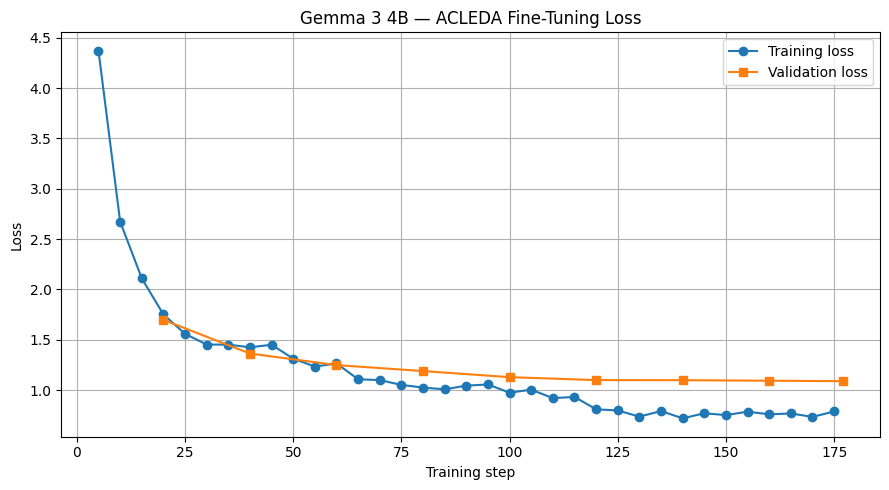

Lowest validation loss: 1.0882941484451294
Step of lowest validation loss: 177


In [ ]:
# Extract logged loss values from the Trainer history.
history = trainer.state.log_history

train_steps = [x["step"] for x in history if "loss" in x and "eval_loss" not in x]
train_losses = [x["loss"] for x in history if "loss" in x and "eval_loss" not in x]

eval_steps = [x["step"] for x in history if "eval_loss" in x]
eval_losses = [x["eval_loss"] for x in history if "eval_loss" in x]

plt.figure(figsize=(9, 5))
if train_losses:
    plt.plot(train_steps, train_losses, marker="o", label="Training loss")
if eval_losses:
    plt.plot(eval_steps, eval_losses, marker="s", label="Validation loss")
plt.xlabel("Training step")
plt.ylabel("Loss")
plt.title("Gemma 3 4B — ACLEDA Fine-Tuning Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("loss_curve.png", dpi=150)
plt.show()

if eval_losses:
    best_i = min(range(len(eval_losses)), key=eval_losses.__getitem__)
    print("Lowest validation loss:", eval_losses[best_i])
    print("Step of lowest validation loss:", eval_steps[best_i])
else:
    print("No validation loss found. Check the evaluation configuration.")


### Results — complete after running the modified configuration

The previously recorded run used different settings (LoRA alpha 16, dropout 0, learning rate 2e-4 and a linear scheduler). Its metrics must **not** be presented as results from this modified configuration.

After rerunning, record actual values:

| Measure | New experiment result |
|---|---:|
| Training examples | Record actual output |
| Validation examples | Record actual output |
| Epochs completed | Record actual output |
| Total training steps | Record actual output |
| Trainable parameters | Record actual output |
| Final training loss | Record actual output |
| Lowest validation loss | Record actual output |
| Runtime | Record actual output |
| Peak GPU memory | Record actual output |

Do not estimate or copy previous values. Loss measures the training objective; it does not alone prove factual answer quality.

## 12. Compare GOLD, BASE, and TUNED

- **GOLD**: expected answer from the dataset.
- **BASE**: Gemma 3 before fine-tuning.
- **TUNED**: Gemma 3 after fine-tuning.

Check factual correctness, relevance, completeness, Khmer clarity, and unsupported details. A fluent answer can still be wrong.


### Observed comparison in this run

For the first displayed question, the GOLD answer says that small-business loans are offered in Khmer riel, US dollars, and Thai baht. The BASE answer gives a long, mostly unrelated list of loan types and includes mixed-language text. The TUNED answer gives the three currencies directly and is much closer to the GOLD answer.

For the second displayed question, the BASE answer discusses general savings-account rules, while the GOLD answer is specifically about deposits into a retirement fund. The TUNED answer is shorter and more related to the question, but it refers to a children's future account and still does not match the GOLD answer. This is an example of improvement in relevance that is not yet fully correct.

**Overall observation:** Fine-tuning improved the response on the first example and made the second response more focused, but it did not make every answer correct. The test set is very small (only a few examples), so these examples are qualitative evidence, not a reliable overall accuracy score.

**Small evaluation issue:** The printed comparison contains the first question twice because `TEST_QUESTIONS` is selected from validation rows and the validation set can contain more than one answer row for the same question. For a cleaner evaluation, select unique question strings before taking the first three questions.

In [ ]:
tuned_answers = {q: generate_answer(q) for q in TEST_QUESTIONS}

for q in TEST_QUESTIONS:
    gold = next(p["output"] for p in val_pairs if p["input"] == q)
    print("\\nQUESTION:", q)
    print("GOLD :", gold)
    print("BASE :", base_answers[q])
    print("TUNED:", tuned_answers[q])
    print("-" * 80)


\nQUESTION: តើឥណទាននេះមានប្រភេទរូបបិយប័ណ្ណអ្វីខ្លះ
GOLD : សម្រាប់ឥណទានអាជីវកម្មខ្នាតតូច ត្រូវបានផ្តល់ជូនជាប្រាក់រៀល ប្រាក់ដុល្លារអាមេរិក និងប្រាក់បាត។
BASE : ឥណទានមានប្រភេទធំៗ ៥ យ៉ាងគឺ ដូចខាងក្រោមនេះ តាមរយៈរូបបិយប័ណ្ណ:

1.  **ឥណទានបញ្ជាក់ទ្រព្យ (Mortgage Loan):** ឥណទានប្រភេទនេះ គឺសម្រាប់ទិញ ឬស 건립 ធ្លី ផ្ទាល់ខ្លួន។ រូបបិយប័ណ្ណនឹងភ្ជាប់មកជាមួយទ្រព្យសម្បត្តិដែលទិញ ឬស 건립 ដែលជាទ្រព្យសម្បត្តិ Guarantee ឥណទាន។
2.  **ឥណទានបញ្ជាក់ទ្រព្យលើមូលធనాన్నిលើមូលធనం (Lien Loan):** ឥណទានប្រភេទនេះ គឺសម្រាប់ទិញ ឬស 건립 ទ្រព្យសម្បត្តិ ដែលជាទ្រព្យសម្បត្តិ Guarantee ឥណទាន។
3.  **ឥណទានពន្ធការងារ (Payroll Loan):** ឥណទានប្រភេទនេះ គឺសម្រាប់ផ្តល់ឥណទានដល់និយោបត្រ주ករយៈពេល 30-60ថ្ងៃ សម្រាប់បង់ប្រាក់ជូននិយោបត្រ주ករយៈពេល 30-60ថ្ងៃ។
4.  **ឥណទានស 건립អាជីវកម្ម (Business Loan):** ឥណទានប្រភេទនេះ គឺសម្រាប់ស 건립 អាជីវកម្ម ឬកសាង ธุรกิจ។ រូបបិយប័ណ្ណនឹងភ្ជាប់មកជាមួយទ្រព្យសម្បត្តិ ឬ Assets ដែលស 건립 ជាមួយនឹងឥណទាន។
5.  **ឥណទាន personale (Personal Loan):** ឥណទានប្រភេទនេះ គឺសម្រាប់ប្រើប្រាស់ personale ដូចជា ថ្លៃព្យាបាល ថ្លៃសិក្សា ឬការស 건립 ផ

## 13. Save the LoRA adapter

The adapter contains the learned LoRA parameters. It is not a complete standalone copy of the 4B base model. To use it later, load the compatible base model and attach the adapter.

Do not upload private access tokens or secrets in a shared notebook.


In [ ]:
model.save_pretrained(CONFIG["lora_dir"])
tokenizer.save_pretrained(CONFIG["lora_dir"])
print("Saved adapter to:", CONFIG["lora_dir"])


Unsloth: Restored added_tokens_decoder metadata in gemma-3-4b-aclede-qa-lora/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in gemma-3-4b-aclede-qa-lora.


Saved adapter to: gemma-3-4b-aclede-qa-lora


## 14. Second-dataset experiment — status

This notebook demonstrates one dataset experiment: ACLEDA Khmer question-answering.

Changing hyperparameters while keeping the same dataset is a **hyperparameter experiment**, not a second-dataset experiment.

If a second dataset is required:
1. Select the second dataset specified by the teacher.
2. Verify non-empty question/input and answer/output fields.
3. Prepare its train/validation split.
4. Keep the model and evaluation procedure consistent for a fair comparison.
5. Train a separate model and save it to a separate output directory.
6. Record actual losses, runtime, memory use, and generated examples.

Until this second run is completed, report it as pending.

In [ ]:
# This cell only illustrates a separate experiment configuration.
# It does NOT train a second model or complete the second-dataset requirement.
EXPERIMENT_CONFIG = CONFIG.copy()
EXPERIMENT_CONFIG["num_train_epochs"] = 2
EXPERIMENT_CONFIG["output_dir"] = "/content/drive/MyDrive/ACLEDA_Gemma3_outputs_2epoch"
print("Example epochs:", EXPERIMENT_CONFIG["num_train_epochs"])
print("Example output directory:", EXPERIMENT_CONFIG["output_dir"])

2 outputs_2_epochs


In [ ]:
import os

os.makedirs(CONFIG["lora_dir"], exist_ok=True)
model.save_pretrained(CONFIG["lora_dir"])
tokenizer.save_pretrained(CONFIG["lora_dir"])
print("Saved LoRA adapter and tokenizer to:", CONFIG["lora_dir"])

Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/I5-ADV/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in /content/drive/MyDrive/I5-ADV.


Successfully saved the model and tokenizer to: /content/drive/MyDrive/I5-ADV
